# Imputation: median fill then rank vs rank then 0

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from eda_data import *

In [2]:
chars = char_names()
df = add_n_missing(is_universe(), chars)
month = df["DATE"].unique().sort()[len(df["DATE"].unique()) // 2]
cols = ["realestate", "stdacc", "secured", "pchsale_pchinvt", "acc", "bm", "mom12m", "rd_mve"]
g = df.filter(pl.col("DATE") == month).select(["DATE"] + cols)
median_then_rank = rank_normalise(g.with_columns([pl.col(c).fill_null(pl.col(c).median()) for c in cols]), cols)
rank_then_zero = rank_normalise(g, cols).with_columns([pl.col(c).fill_null(0.0) for c in cols])
print("month:", month)

month: 19980130


## Distribution of normalised values in one month

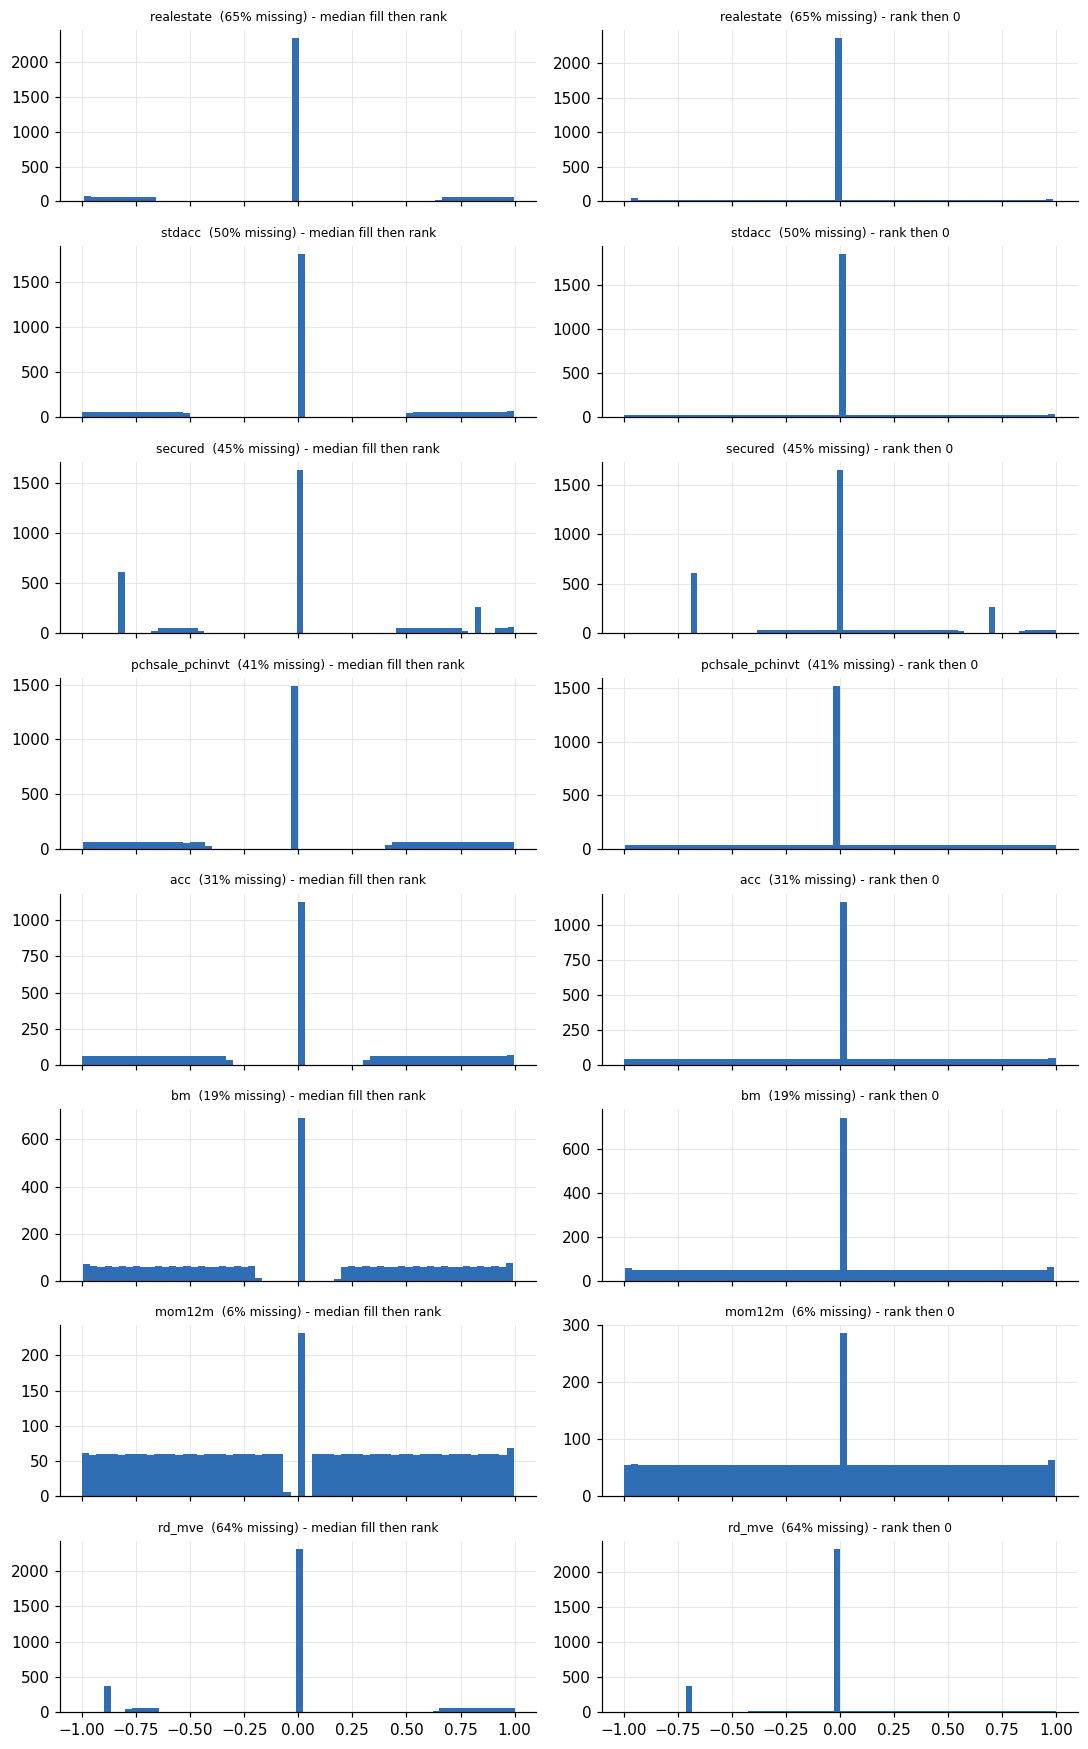

In [3]:
fig, axes = plt.subplots(len(cols), 2, figsize=(10, 2.0 * len(cols)), sharex=True)
for row, c in enumerate(cols):
    miss = g[c].null_count() / g.height
    for col, (name, d) in enumerate([("median fill then rank", median_then_rank), ("rank then 0", rank_then_zero)]):
        ax = axes[row, col]
        ax.hist(d[c], bins=60, color=BLUE)
        ax.set_title(f"{c}  ({miss:.0%} missing) - {name}", fontsize=8)
plt.tight_layout(); plt.show()

## Share of values at the single most common normalised value, pooled in-sample

In [4]:
a = rank_normalise(df.with_columns([pl.col(c).fill_null(pl.col(c).median().over("DATE")) for c in chars]), chars)
b = rank_normalise(df, chars).with_columns([pl.col(c).fill_null(0.0) for c in chars])
def top_share(d, c):
    return d.group_by("DATE").agg((pl.col(c).value_counts(sort=True).first().struct.field("count") / pl.len()).alias("s"))["s"].mean()
pile = pl.DataFrame({"char": chars, "missing": [df[c].null_count() / df.height for c in chars],
                     "median_then_rank": [top_share(a, c) for c in chars], "rank_then_zero": [top_share(b, c) for c in chars]})
pile.sort("missing", descending=True)

char,missing,median_then_rank,rank_then_zero
str,f64,f64,f64
"""realestate""",0.6922,0.6978,0.6978
"""rd_sale""",0.6368,0.6377,0.6377
"""rd_mve""",0.6354,0.6362,0.6362
"""stdacc""",0.4832,0.4817,0.4817
"""stdcf""",0.4832,0.4817,0.4817
"""orgcap""",0.4722,0.4711,0.4711
"""secured""",0.4588,0.4607,0.4607
"""grltnoa""",0.4584,0.4574,0.4574
"""pchsale_pchxsga""",0.4293,0.4287,0.4287


## Share of features equal to 0 per firm-month under rank then 0

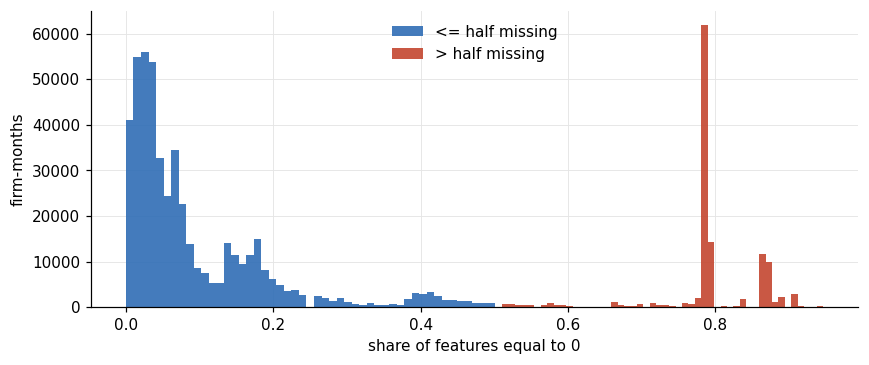

In [5]:
zeros = b.select(pl.sum_horizontal([pl.col(c) == 0 for c in chars]).alias("n_zero"))["n_zero"] / len(chars)
over_half = (df["n_missing"] > len(chars) / 2).to_numpy()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(zeros.to_numpy()[~over_half], bins=50, color=BLUE, alpha=0.9, label="<= half missing")
ax.hist(zeros.to_numpy()[over_half], bins=50, color="#c4462f", alpha=0.9, label="> half missing")
ax.set_xlabel("share of features equal to 0"); ax.set_ylabel("firm-months"); ax.legend(frameon=False); plt.show()

## Vector norm of rank-then-0 features

In [6]:
X = b.select(chars).to_numpy()
norms = np.linalg.norm(X, axis=1)
pl.DataFrame({"over_half_missing": over_half, "norm": norms}).group_by("over_half_missing").agg(
    pl.col("norm").quantile(0.1).alias("p10"), pl.col("norm").median().alias("median"), pl.col("norm").quantile(0.9).alias("p90"))

over_half_missing,p10,median,p90
bool,f64,f64,f64
false,4.3363,5.0752,6.0796
true,1.7610,2.4971,3.2565
